# Deribit Pitch EDA: does crypto sell off into the monthly options settlement after a rally?

**The mechanism.** Deribit holds about 80% of crypto options open interest. The monthly expiry (last Friday of the
month) carries most of it and settles at 08:00 UTC on a 30-minute average of the index (07:30–08:00). After a
rally, open interest is dominated by calls that are near or in the money; dealers who sold them are long the
underlying as a delta hedge. As those calls expire, the hedge is no longer needed and is sold into the settlement window.
The flow is mechanical, on a date fixed months in advance, and it stops at 08:00, so the price should give it
back afterwards.

**The rule (from the 2020–23 data, tested on 2024–26).** On each monthly-expiry Friday, if the coin is up over the
previous 30 days (measured at 06:00 UTC), short the BTC and ETH perpetuals at 06:00 UTC and cover at 08:00 UTC.

**Questions.**
1. Is there a pre-settlement drop on monthly-expiry Fridays, and is it specific to them (not weekly Fridays, not
   Thursdays)?
2. Does it depend on the prior rally, as the dealer-hedge story predicts?
3. Does the rule hold out of sample after costs, and is it robust to the window?
4. Does the price recover after 08:00 (temporary pressure)?

**Data.** Binance USDT-margined perpetuals, 5-minute bars (`Funding Pitch/collect_binance.py`; BTC, ETH, plus SOL/XRP
for breadth), 2020-01 → 2026-09.

**Look-ahead checklist**

| input | known at entry (06:00 UTC on expiry Friday)? |
|---|---|
| which Friday is the monthly expiry | yes: Deribit lists monthly expiries (last Friday) months ahead |
| prior 30-day return | yes: computed from prices up to 06:00 |
| exit at 08:00 UTC | a scheduled time; filled at the 07:55–08:00 bar close |

**Honest disclosure.** The pre-expiry drop was first noticed in an unconditional 2024+ test (`CMEExpiry Pitch`).
The "only after a rally" condition and the 06:00–08:00 window were then set from the mechanism and the 2020–23 data.
So 2024– is out of sample for the rule, but not for the discovery of the effect.

## 1. Data

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
SPLIT = pd.Timestamp("2024-01-01")
def grid(sym):
    k = pd.read_csv(f"../Funding Pitch/data/klines_{sym}.csv", parse_dates=["open_time"])
    k["d"] = k.open_time.dt.normalize(); k["hm"] = k.open_time.dt.strftime("%H:%M")
    return np.log(k.pivot_table(index="d", columns="hm", values="close"))     # close of the bar starting at hm
G = {s: grid(s) for s in ["BTCUSDT", "ETHUSDT", "SOLUSDT", "XRPUSDT"]}
def frame(L):
    df = pd.DataFrame({"prior": (L["05:55"] - L["05:55"].shift(30)) * 1e4}, index=L.index)
    df["dow"] = df.index.dayofweek
    fr = df.dow == 4
    last_fri = pd.Series(False, index=df.index)
    idx = df[fr].groupby(df[fr].index.to_period("M")).tail(1).index
    last_fri[idx] = True
    df["kind"] = np.where(last_fri, "monthly expiry", np.where(fr, "weekly Friday", np.where(df.dow == 3, "Thursday", "other")))
    return df
F = {s: frame(L) for s, L in G.items()}
print({s: (L.index.min().date(), L.index.max().date()) for s, L in G.items()})

{'BTCUSDT': (datetime.date(2020, 1, 1), datetime.date(2026, 9, 30)), 'ETHUSDT': (datetime.date(2020, 1, 1), datetime.date(2026, 9, 30)), 'SOLUSDT': (datetime.date(2020, 9, 14), datetime.date(2026, 9, 30)), 'XRPUSDT': (datetime.date(2020, 1, 6), datetime.date(2026, 9, 30))}


## 2. The intraday path on expiry mornings
**What this does.** Average cumulative return from 00:00 to 12:00 UTC on monthly-expiry Fridays, weekly Fridays and
Thursdays, for BTC and ETH, split by whether the prior 30 days were up or down, 2020–23 vs 2024–. Rebased to 0 at
06:00. The settlement window (07:30–08:00) is shaded.

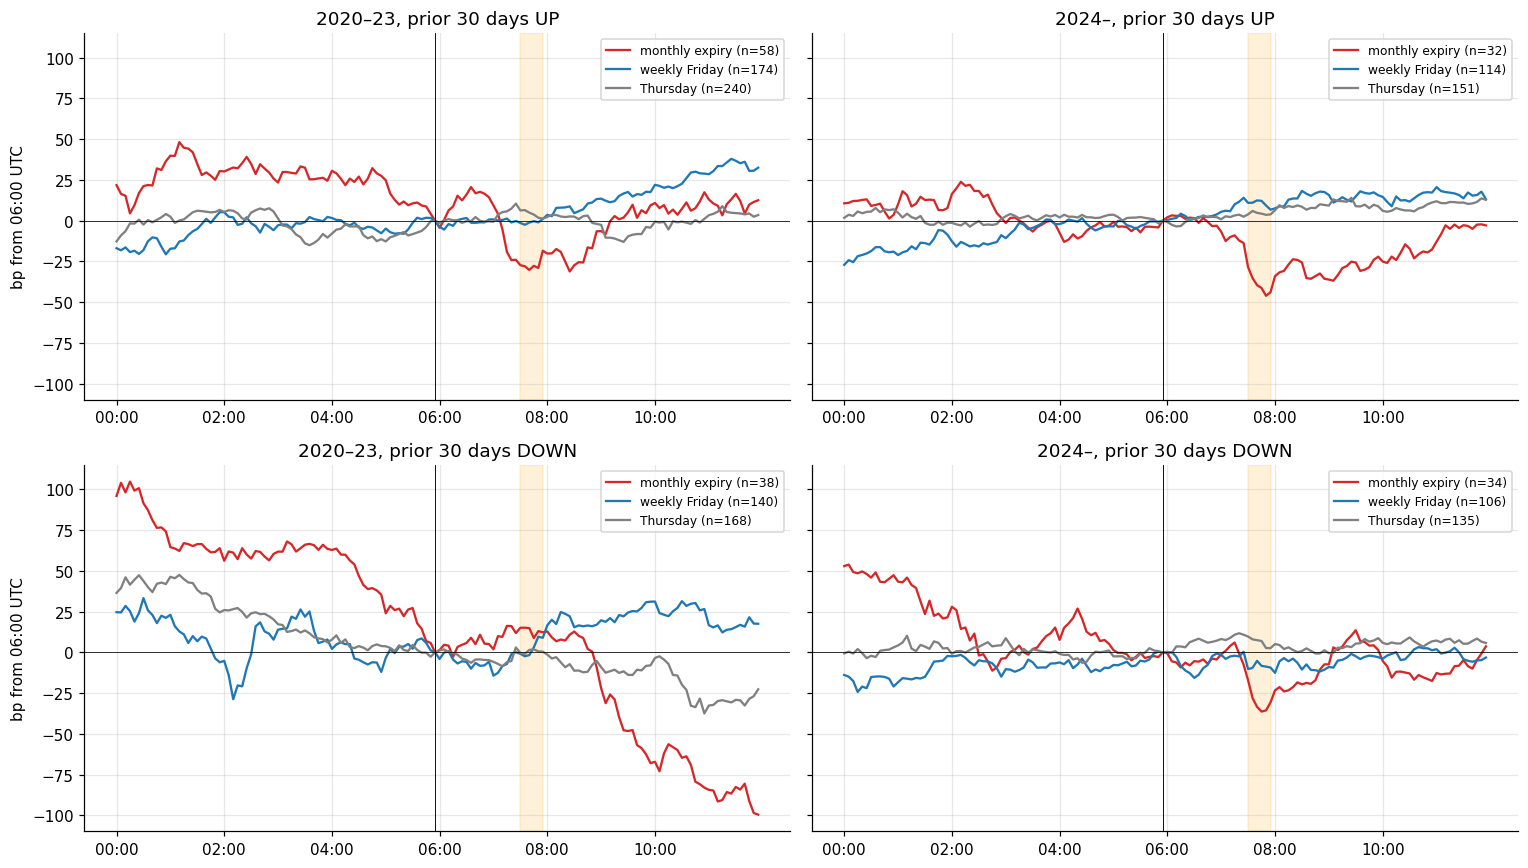

In [2]:
cols = [c for c in G["BTCUSDT"].columns if "00:00" <= c <= "11:55"]
fig, ax = plt.subplots(2, 2, figsize=(14, 8), sharey=True)
for a, (per, m) in zip(ax[0], [("2020–23", lambda i: i < SPLIT), ("2024–", lambda i: i >= SPLIT)]):
    for kind, c in [("monthly expiry", "C3"), ("weekly Friday", "C0"), ("Thursday", "gray")]:
        paths = []
        for s in ["BTCUSDT", "ETHUSDT"]:
            L, f = G[s], F[s]
            sel = f.index[(f.kind == kind) & m(f.index) & (f.prior > 0)]
            P = (L.loc[sel, cols].sub(L.loc[sel, "05:55"], axis=0) * 1e4)
            paths.append(P)
        P = pd.concat(paths); a.plot(range(len(cols)), P.mean(), c=c, label=f"{kind} (n={len(P)})")
    a.set_title(f"{per}, prior 30 days UP"); a.axvspan(cols.index("07:30"), cols.index("07:55"), color="orange", alpha=0.15)
    a.axvline(cols.index("05:55"), c="k", lw=0.6); a.legend(fontsize=8)
for a, (per, m) in zip(ax[1], [("2020–23", lambda i: i < SPLIT), ("2024–", lambda i: i >= SPLIT)]):
    for kind, c in [("monthly expiry", "C3"), ("weekly Friday", "C0"), ("Thursday", "gray")]:
        paths = []
        for s in ["BTCUSDT", "ETHUSDT"]:
            L, f = G[s], F[s]
            sel = f.index[(f.kind == kind) & m(f.index) & (f.prior <= 0)]
            paths.append(L.loc[sel, cols].sub(L.loc[sel, "05:55"], axis=0) * 1e4)
        P = pd.concat(paths); a.plot(range(len(cols)), P.mean(), c=c, label=f"{kind} (n={len(P)})")
    a.set_title(f"{per}, prior 30 days DOWN"); a.axvspan(cols.index("07:30"), cols.index("07:55"), color="orange", alpha=0.15)
    a.axvline(cols.index("05:55"), c="k", lw=0.6); a.legend(fontsize=8)
for a in ax.flat:
    a.set_xticks(range(0, len(cols), 24)); a.set_xticklabels(cols[::24]); a.axhline(0, c="k", lw=0.5)
ax[0, 0].set_ylabel("bp from 06:00 UTC"); ax[1, 0].set_ylabel("bp from 06:00 UTC")
plt.tight_layout(); plt.show()

## 3. Pre-settlement return by day type and prior trend
**What this does.** 06:00 → 08:00 UTC return (bp) for each coin, by day type, prior trend and era, with t-stats
against Thursdays.

In [3]:
rows = []
for s in G:
    L, f = G[s], F[s]
    w = (L["07:55"] - L["05:55"]) * 1e4
    for per, m in [("2020–23", f.index < SPLIT), ("2024–", f.index >= SPLIT)]:
        base = w[m & (f.kind == "Thursday").values].dropna()
        for kind in ["monthly expiry", "weekly Friday"]:
            for tr, tm in [("prior up", f.prior > 0), ("prior down", f.prior <= 0)]:
                x = w[m & (f.kind == kind).values & tm.values].dropna()
                rows.append({"coin": s[:-4], "era": per, "day": kind, "trend": tr, "n": len(x), "06→08 bp": x.mean(),
                             "t vs Thursdays": stats.ttest_ind(x, base, equal_var=False)[0] if len(x) > 2 else np.nan})
print(pd.DataFrame(rows).round(2).to_string(index=False))

coin     era            day      trend  n  06→08 bp  t vs Thursdays
 BTC 2020–23 monthly expiry   prior up 28    -16.96           -0.99
 BTC 2020–23 monthly expiry prior down 20      5.13            0.41
 BTC 2020–23  weekly Friday   prior up 84      3.51            0.51
 BTC 2020–23  weekly Friday prior down 73      7.66            0.53
 BTC   2024– monthly expiry   prior up 18    -33.82           -3.47
 BTC   2024– monthly expiry prior down 15    -30.13           -2.08
 BTC   2024–  weekly Friday   prior up 61      8.98            0.64
 BTC   2024–  weekly Friday prior down 49     -8.92           -0.95
 ETH 2020–23 monthly expiry   prior up 30    -19.84           -1.35
 ETH 2020–23 monthly expiry prior down 18     20.46            0.66
 ETH 2020–23  weekly Friday   prior up 90     -1.30           -0.37
 ETH 2020–23  weekly Friday prior down 67     10.41            0.32
 ETH   2024– monthly expiry   prior up 14    -56.89           -3.28
 ETH   2024– monthly expiry prior down 19    -31

**Interpretation.**
- **The drop belongs to monthly expiries after a rally.** In 2020–23, monthly expiries after an up month fall
  (BTC −17bp, ETH −20bp) while after a down month they rise (+5 / +20bp). Weekly Fridays and Thursdays show nothing
  like it. That is the dealer-hedge prediction: more near-the-money calls after a rally, more hedge to sell at expiry.
- **Since 2024 it is bigger and broad:** BTC −34bp, ETH −57bp after up months. Down months fall too, consistent
  with call-heavy open interest throughout the 2024–26 bull market. SOL and XRP show the same sign.

## 4. The rule, out of sample
**Rule.** Monthly-expiry Friday, prior 30 days up → short BTC and ETH perps at 06:00, cover at 08:00 UTC; P&L averaged
across the two coins per expiry; costs 4bp (maker) / 8bp (taker) round trip. 2020–23 in-sample, 2024– out of sample.

               period  cost bp  trades  bp/trade    t  hit   worst  Sharpe/yr
  2020–23 (in-sample)        0      31     20.32 1.42 0.48 -140.61       0.72
  2020–23 (in-sample)        4      31     16.32 1.14 0.48 -144.61       0.58
  2020–23 (in-sample)        8      31     12.32 0.86 0.48 -148.61       0.44
2024– (out-of-sample)        0      19     45.66 3.21 0.79  -61.43       2.00
2024– (out-of-sample)        4      19     41.66 2.93 0.74  -65.43       1.82
2024– (out-of-sample)        8      19     37.66 2.65 0.74  -69.43       1.65


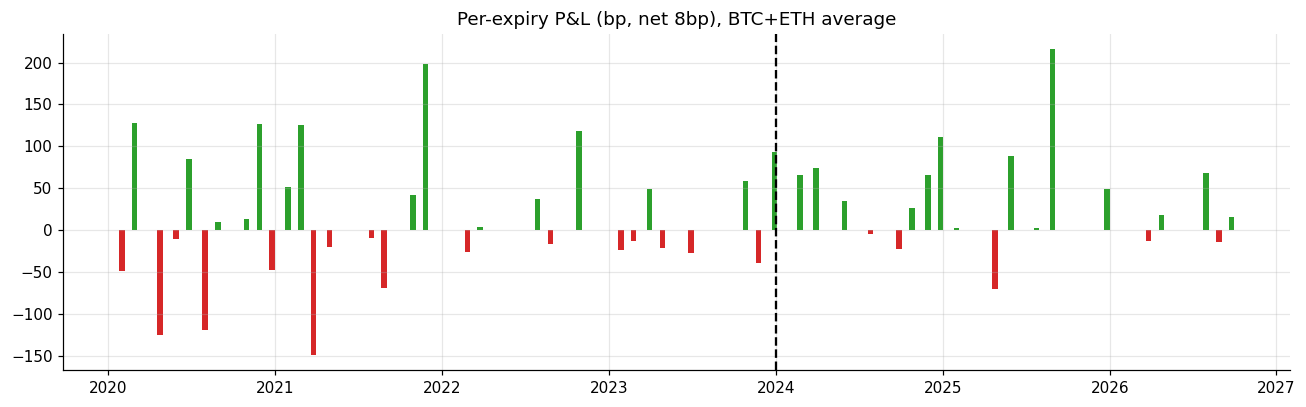

by year (net 8bp): {2020: {'mean': 1.0, 'count': 10}, 2021: {'mean': 22.0, 'count': 8}, 2022: {'mean': 24.0, 'count': 5}, 2023: {'mean': 10.0, 'count': 8}, 2024: {'mean': 44.0, 'count': 8}, 2025: {'mean': 48.0, 'count': 6}, 2026: {'mean': 15.0, 'count': 5}}


In [4]:
def trades(a="05:55", b="07:55", kinds=("monthly expiry",), cond=lambda f: f.prior > 0, coins=("BTCUSDT", "ETHUSDT")):
    out = []
    for s in coins:
        L, f = G[s], F[s]
        w = (L[b] - L[a]) * 1e4
        sel = f.kind.isin(kinds) & cond(f)
        out.append((-w[sel.values]).rename(s))
    return pd.concat(out, axis=1).mean(1).dropna()
x = trades()
rows = []
for per, m in [("2020–23 (in-sample)", x.index < SPLIT), ("2024– (out-of-sample)", x.index >= SPLIT)]:
    for c in [0, 4, 8]:
        y = x[m] - c; yrs = (y.index.max() - y.index.min()).days / 365.25
        rows.append({"period": per, "cost bp": c, "trades": len(y), "bp/trade": y.mean(), "t": y.mean() / y.std() * np.sqrt(len(y)),
                     "hit": (y > 0).mean(), "worst": y.min(), "Sharpe/yr": y.mean() / y.std() * np.sqrt(len(y) / yrs)})
print(pd.DataFrame(rows).round(2).to_string(index=False))
y = x - 8
fig, ax = plt.subplots(figsize=(12, 3.8)); ax.bar(y.index, y.values, width=12, color=np.where(y > 0, "C2", "C3"))
ax.axvline(SPLIT, c="k", ls="--"); ax.set_title("Per-expiry P&L (bp, net 8bp), BTC+ETH average"); plt.tight_layout(); plt.show()
print("by year (net 8bp):", y.groupby(y.index.year).agg(["mean", "count"]).round(0).to_dict("index"))

## 5. Robustness: window, placebo days, what happens after 08:00, breadth

In [5]:
rows = []
specs = {"rule 06:00→08:00": dict(), "07:00→08:00": dict(a="06:55"), "04:00→08:00": dict(a="03:55"),
         "settlement average only 07:30→08:00": dict(a="07:25"),
         "placebo: weekly Fridays 06→08": dict(kinds=("weekly Friday",)), "placebo: Thursdays 06→08": dict(kinds=("Thursday",)),
         "monthly, prior DOWN": dict(cond=lambda f: f.prior <= 0), "monthly, all": dict(cond=lambda f: f.prior == f.prior),
         "SOL+XRP (breadth)": dict(coins=("SOLUSDT", "XRPUSDT"))}
for nm, kw in specs.items():
    z = trades(**kw) - 8
    for per, m in [("2020–23", z.index < SPLIT), ("2024–", z.index >= SPLIT)]:
        y = z[m]; rows.append({"spec": nm, "era": per, "n": len(y), "bp/trade net 8": y.mean(), "t": y.mean() / y.std() * np.sqrt(len(y))})
after = trades(a="07:55", b="09:55")      # sign: positive = price FELL after 08:00 (short still profitable)
for per, m in [("2020–23", after.index < SPLIT), ("2024–", after.index >= SPLIT)]:
    y = -after[m]; rows.append({"spec": "AFTER settlement 08:00→10:00: price change, gross (+ = recovery)", "era": per, "n": len(y), "bp/trade net 8": y.mean(), "t": y.mean() / y.std() * np.sqrt(len(y))})
print(pd.DataFrame(rows).round(2).to_string(index=False))

                                                            spec     era   n  bp/trade net 8     t
                                                rule 06:00→08:00 2020–23  31           12.32  0.86
                                                rule 06:00→08:00   2024–  19           37.66  2.65
                                                     07:00→08:00 2020–23  31           24.54  1.74
                                                     07:00→08:00   2024–  19           36.14  2.85
                                                     04:00→08:00 2020–23  31           34.05  1.35
                                                     04:00→08:00   2024–  19           38.72  2.36
                             settlement average only 07:30→08:00 2020–23  31          -14.60 -1.43
                             settlement average only 07:30→08:00   2024–  19           19.36  2.39
                                   placebo: weekly Fridays 06→08 2020–23 101           -4.50 -0.43
          

**Interpretation.**
- **Out of sample the rule works and survives costs:** +38bp per expiry net of 8bp (t 2.65), 74% hit rate, 19
  expiries 2024–26. Every year is positive: 2024 +44, 2025 +48, 2026 (to September) +15bp. In-sample it was +12bp (t 0.9), positive
  in every year 2020–23 (+1, +22, +24, +10).
- **The window choice does not drive it:** 07:00→08:00 and 04:00→08:00 give the same out-of-sample result (t 2.4–2.9).
  The settlement-average half hour alone is positive out of sample (t 2.4) but negative in-sample, so most of the
  selling comes before the averaging window, consistent with dealers getting ahead of the fixing.
- **Placebos go the other way:** the same short on weekly Fridays or Thursdays loses after costs (prices drift up
  those mornings). That makes the monthly result conservative, not an artifact of a general Friday-morning drop.
- **The price recovers after 08:00** (+23bp gross over the next two hours since 2024, t ≈ 1.4), the shape of
  temporary pressure that ends at the fixing.
- **Breadth:** SOL and XRP (Deribit lists fewer options on them) show the same sign since 2024.

## 6. Takeaways

| question | answer |
|---|---|
| Is there a pre-settlement drop on monthly expiries? | **Yes, after rallies.** 2020–23: −17 to −20bp after up months, none after down months. 2024–: −34 (BTC) / −57bp (ETH). |
| Specific to the monthly expiry? | Yes. Weekly Fridays and Thursdays show no drop (shorting them loses). |
| Mechanism | Dealer delta-hedge unwinding into the 08:00 UTC settlement as calls expire; the price recovers after 08:00. |
| Tradable | **Yes.** Short BTC/ETH perps 06:00→08:00 on monthly-expiry Fridays after an up month: +38bp/trade net of 8bp out of sample (t 2.65, 74% hit), every year 2020–26 positive; in-sample +12bp (t 0.9). |

**Verdict: promising and tradable, with a small sample.** It has a mechanical, calendar-fixed flow (dealers unwinding
option hedges into a known settlement), the direction the mechanism predicts (after rallies, only on the monthly
expiry, recovering after the fixing), clean placebos, positive results in all seven years, and the most liquid
instrument in crypto (perps, 2 hours a month, so capacity is not an issue).

**Caveats.**
- **Small sample:** 19 out-of-sample expiries.
- **Weak in-sample:** t 0.9.
- **Discovery overlaps the test period:** the effect was first noticed on 2024+ data before the rule was framed from
  2020–23.
- **Mechanism inferred, not observed:** confirming it needs Deribit open interest by strike (not free), e.g. the
  call/put OI ratio and gamma at the expiry.

**Next steps.** Get historical Deribit open interest by strike (Deribit history API / Tardis) to size the expiring call
delta, and test whether the drop scales with it. Paper-trade the next expiries.